# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Работу запускал на своем компьютере: Windows, NVIDIA GeForce RTX 5070.
Взял [rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2) с лицензией MIT
и русскую часть [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural)
с лицензией CC BY-NC-SA 4.0. Обязательные задания 1–5 выполнены, бонусы не делал.

Пользовался шаблоном задания, карточками модели и датасета,
[описанием обучения rubert-tiny](https://habr.com/ru/articles/562064/),
[статьей автора про rubert-tiny2](https://habr.com/ru/articles/669674/),
[карточкой RuBERT-base](https://huggingface.co/DeepPavlov/rubert-base-cased),
[документацией Trainer](https://huggingface.co/docs/transformers/main_classes/trainer)
и [seqeval](https://github.com/chakki-works/seqeval).

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

W1122 13:59:20.153000 29596 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.11.0+cu128, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda NVIDIA GeForce RTX 5070


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = set()   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'   # ваш код: id модели на Hugging Face Hub
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}
BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Я выбрал rubert-tiny2, потому что данные на русском, а небольшая модель позволяет быстро
проверить обучение и абляцию. У нее около 29 млн параметров, три слоя и словарь из 83 828 токенов;
в моем замере прямой проход батча 32 × 64 токена занял 2,5 мс на RTX 5070.
Это базовый энкодер, поэтому для NER я добавляю новую голову и обучаю ее вместе с моделью.

По [описанию автора](https://habr.com/ru/articles/562064/), исходный rubert-tiny обучался на парах
русских и английских предложений из Яндекс.Переводчика, OPUS-100 и Tatoeba.
В [версии tiny2](https://habr.com/ru/articles/669674/) словарь расширили и продолжили обучение
на предсказании скрытых токенов, определении связи между предложениями и приближении эмбеддингов LaBSE.
[Карточка tiny2](https://huggingface.co/cointegrated/rubert-tiny2) указывает, что эта версия ориентирована на русский язык.
Я ожидал, что после дообучения она сможет находить сущности, но редкие названия могут даваться ей хуже.

Для сравнения, [RuBERT-base](https://huggingface.co/DeepPavlov/rubert-base-cased) тоже работает с русским,
обучался на Википедии и новостях, но у него около 180 млн параметров и 12 слоев.
Я ожидал бы от него большего расхода памяти и времени, а возможный выигрыш на NER надо проверять отдельно:
в карточках нет сопоставимого результата для моего эксперимента.
У tiny2 лицензия MIT. Полный commit hash я зафиксировал, чтобы при повторном запуске загрузились
те же веса, конфигурация и токенизатор: с `main` они со временем могут измениться.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    # ваш код
    base = model.base_model
    layers = base.encoder.layer
    count = lambda module: sum(p.numel() for p in module.parameters())
    embeddings = count(base.embeddings)
    encoder = count(layers)
    head = count(model.classifier)
    total = count(model)
    return dict(embeddings=embeddings, encoder=encoder, head=head,
                other=total - embeddings - encoder - head,
                layers=[count(layer) for layer in layers])

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
# ваш код
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids:', enc['input_ids'].shape)
print('attention_mask:', enc['attention_mask'].shape)
print('hidden_states:', [h.shape for h in out.hidden_states])
print('logits:', out.logits.shape)

input_ids: torch.Size([2, 11])
attention_mask: torch.Size([2, 11])
hidden_states: [torch.Size([2, 11, 312]), torch.Size([2, 11, 312]), torch.Size([2, 11, 312]), torch.Size([2, 11, 312])]
logits: torch.Size([2, 11, 7])


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 2.5 ms на NVIDIA GeForce RTX 5070


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** После токенизации получились `input_ids` и `attention_mask` формы `(2, 11)`:
два предложения по 11 позиций с учетом дополнения до одной длины.
Эмбеддинги превращают их в тензор `(2, 11, 312)`, и три слоя энкодера сохраняют эту форму.
Поэтому в `hidden_states` четыре тензора: выход эмбеддингов и выход каждого из трех слоев.
Голова дает `logits` формы `(2, 11, 7)` — оценки семи демонстрационных тегов;
для моего датасета тегов уже девять.

Больше всего параметров в эмбеддингах: 26 794 560, то есть 92,1% модели.
Основная причина — большая таблица словаря: 83 828 векторов по 312 чисел.
Токены обмениваются контекстом в энкодере, а линейная голова обрабатывает каждую позицию отдельно.
Позиций получилось больше, чем слов, потому что некоторые слова разбились на сабворды,
плюс добавились специальные токены и padding.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)

In [13]:
DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', None   # ваш код
files = {split: f'hf://datasets/{DATASET_ID}@74c9b9dca034bb1606a6769457983904bd976803/data/{name}-00000-of-00001.parquet'
         for split, name in [('train', 'train_ru'), ('validation', 'val_ru'), ('test', 'test_ru')]}
raw = load_dataset('parquet', data_files=files)
limits = {'train': 12000, 'validation': 1500, 'test': 1500}
raw = DatasetDict({split: raw[split].shuffle(seed=SEED).select(range(min(limit, len(raw[split]))))
                   for split, limit in limits.items()})
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']   # ваш код: список BIO-тегов, LABEL_NAMES[i] - тег с id i

train {'sentences': 12000, 'entities': {'LOC': 8915, 'ORG': 2614, 'MISC': 3155, 'PER': 4300}, 'mean_span': 1.3033080488832702, 'mean_sentence': 19.562916666666666}


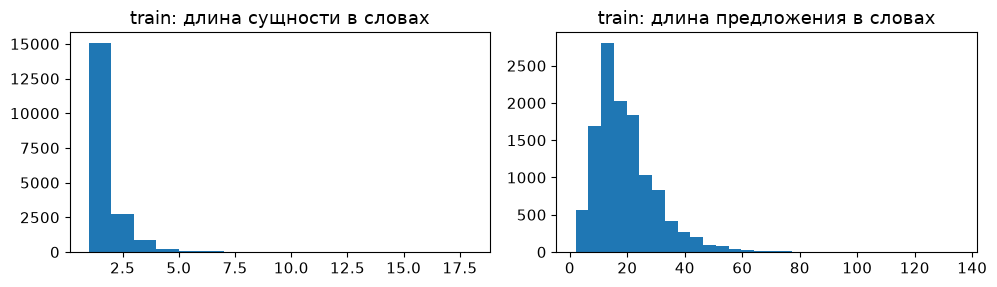

validation {'sentences': 1500, 'entities': {'LOC': 1118, 'PER': 579, 'ORG': 361, 'MISC': 349}, 'mean_span': 1.3286248442044037, 'mean_sentence': 18.768}


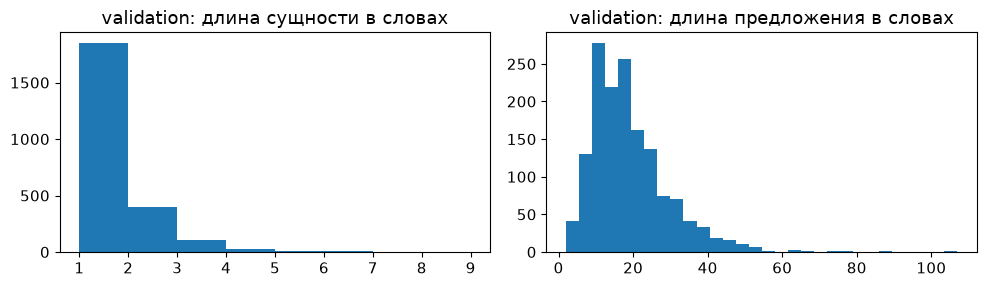

test {'sentences': 1500, 'entities': {'ORG': 417, 'LOC': 1174, 'MISC': 365, 'PER': 472}, 'mean_span': 1.3476112026359144, 'mean_sentence': 18.683333333333334}


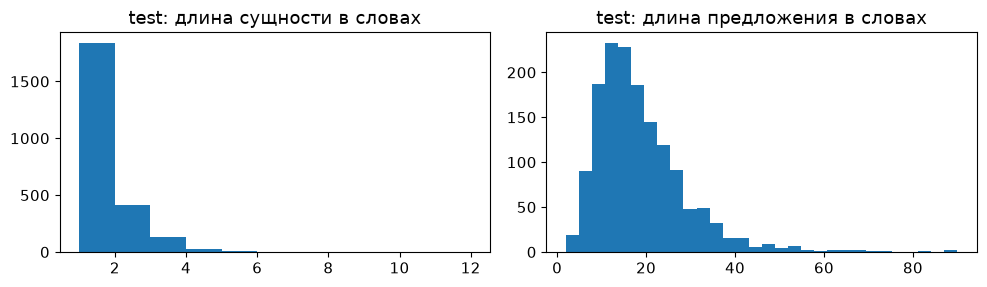

In [14]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
# ваш код
from seqeval.metrics.sequence_labeling import get_entities

stats = {}
for split, ds in raw.items():
    spans = [span for row in ds['ner_tags'] for span in get_entities([LABEL_NAMES[i] for i in row])]
    counts = collections.Counter(kind for kind, start, end in spans)
    span_lengths = [end - start + 1 for kind, start, end in spans]
    sentence_lengths = [len(words) for words in ds['tokens']]
    stats[split] = dict(sentences=len(ds), entities=dict(counts),
                        mean_span=float(np.mean(span_lengths)), mean_sentence=float(np.mean(sentence_lengths)))
    print(split, stats[split])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].hist(span_lengths, bins=range(1, max(span_lengths) + 2))
    axes[0].set_title(f'{split}: длина сущности в словах')
    axes[1].hist(sentence_lengths, bins=30)
    axes[1].set_title(f'{split}: длина предложения в словах')
    plt.tight_layout()
    plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Я взял русскую часть [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural):
это тексты Википедии с автоматической разметкой, которую получили с помощью BabelNet и нейросетей.
Лицензия датасета — CC BY-NC-SA 4.0. Здесь четыре типа: PER — люди, ORG — организации,
LOC — места и MISC — остальные сущности, например названия произведений.
Для работы я случайно выбрал 12 000 предложений из train и по 1500 из validation и test с seed=0;
исходное разделение на сплиты сохранил.

Число сущностей в выбранных подмножествах:

| Сплит | PER | ORG | LOC | MISC |
|---|---:|---:|---:|---:|
| train | 4300 | 2614 | 8915 | 3155 |
| validation | 579 | 361 | 1118 | 349 |
| test | 472 | 417 | 1174 | 365 |

В train реже всего встречаются ORG, а LOC заметно больше остальных типов.
Средняя длина сущности — около 1,3 слова, предложения — около 19 слов во всех трех сплитах.
В среднем тексты короткие, но на гистограммах есть и длинные предложения, которые могут обрезаться.
Думаю, основные сложности здесь — дисбаланс типов, редкие названия и шум автоматической разметки.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    # ваш код
    spans = []
    start = kind = None
    for i, tag in enumerate(list(tags) + ['O']):
        prefix, current = ('O', None) if tag == 'O' else tag.split('-', 1)
        if kind is not None and (prefix != 'I' or current != kind):
            spans.append((start, i, kind))
            start = kind = None
        if current is not None and kind is None:
            start, kind = i, current
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    # ваш код
    tags = ['O'] * n_words
    for start, end, kind in spans:
        if not 0 <= start < end <= n_words or any(t != 'O' for t in tags[start:end]):
            raise ValueError('Неправильные или пересекающиеся спаны')
        tags[start:end] = ['B-' + kind] + ['I-' + kind] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    # ваш код
    result = []
    previous = None
    for word_id in word_ids:
        if word_id is None:
            result.append(-100)
        elif word_id != previous:
            result.append(word_labels[word_id])
        elif b_to_i is None:
            result.append(-100)
        else:
            label = word_labels[word_id]
            result.append(b_to_i.get(label, label))
        previous = word_id
    return result

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
# ваш код
Path('data').mkdir(exist_ok=True)
roundtrip = {}
for split, ds in raw.items():
    path = Path('data') / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in ds:
            tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            f.write(json.dumps(dict(tokens=ex['tokens'], spans=bio_to_spans(tags)), ensure_ascii=False) + '\n')
    changed = 0
    with path.open(encoding='utf-8') as f:
        for ex, line in zip(ds, f, strict=True):
            restored = json.loads(line)
            tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            back = spans_to_bio(restored['spans'], len(ex['tokens']))
            assert restored['tokens'] == ex['tokens']
            assert bio_to_spans(tags) == bio_to_spans(back)
            changed += tags != back
    roundtrip[split] = changed
    print(split, 'проверено:', len(ds), 'неканонический BIO:', changed)

for ex in raw['train'].select(range(3)):
    print(' '.join(ex['tokens']))
    print([(a, b, t, ' '.join(ex['tokens'][a:b]))
           for a, b, t in bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])])

tag_ids = {tag: i for i, tag in enumerate(LABEL_NAMES)}
raw = raw.map(lambda ex: {'ner_tags': [tag_ids[t] for t in spans_to_bio(
    bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']]), len(ex['tokens']))]})

train проверено: 12000 неканонический BIO: 414
validation проверено: 1500 неканонический BIO: 46
test проверено: 1500 неканонический BIO: 56
Работы по строительству первоначальной инфраструктуры аэропорта начались в 1937 году на месте девяти сельскохозяйственных угодий , выкупленных муниципальным комитетом Торонто у частных владельцев .
[(19, 20, 'LOC', 'Торонто')]
Карьеру профессионального футболиста начинал на позиции полузащитника в скромном « Клайде » .
[(9, 12, 'ORG', '« Клайде »')]
В паре с ней - олимпийский чемпион 2006 года , двукратный чемпион мира , трёхкратный чемпион Европы , трёхкратный победитель финалов Гран-при , чемпион мира среди юниоров 1996 года , и трёхкратный чемпион России .
[(21, 22, 'MISC', 'Гран-при'), (33, 34, 'LOC', 'России')]


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(tokenizer(ex['tokens'], is_split_into_words=True, truncation=False)['input_ids']) > MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 12000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 1500
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']
train: проверено 11990 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 178
[CLS]            None  -100
Работы              0  O
по                  1  O
строительству       2  O
первоначальной      3  O
инфраструктуры      4  O
аэропорта           5  O
начались            6  O
в                   7  O
1937                8  O
году                9  O
на                 10  O
месте              11  O
девяти             12  O
сельскохозяйственных   13  O
угодий             14  O
,                  15  O
выкуп              16  O
##ленных           16  -100
муниципальным      17  O
комитетом          1

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метку ставлю на первый сабворд, чтобы длинное слово не учитывалось в loss несколько раз
только из-за того, что токенизатор разбил его на части. Остальным сабвордам и специальным токенам
ставлю `-100`: такие позиции cross-entropy пропускает.

При проверке BIO → спаны → BIO теги изменились в 414 предложениях train, 46 validation и 56 test:
например, `I-X` без начала сущности превращается в `B-X`. При этом сами спаны совпали во всех примерах,
так что я привел теги к обычному BIO, не меняя сущности. Вложенность здесь отдельно разбирать не пришлось:
на каждое слово уже дан один тег.

В train по лимиту 128 сабвордов обрезалось 10 предложений из 12 000;
всего 178 слов оказались за обрезкой или не получили сабворда.
Этот счетчик объединяет обе причины, поэтому отдельно число слов без сабвордов я по нему назвать не могу.
В остальных 11 990 предложениях метки слов восстановились полностью.
При оценке невидимые модели слова получают `O`, поэтому сущности на этих позициях могут быть пропущены,
а recall и F1 — снижены.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    # ваш код
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: count.most_common(1)[0][0] for word, count in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    # ваш код
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}   # ваш код: baseline['majority'] и baseline['random_head'] - словари entity_scores

tagger = fit_majority_tagger(data['train']['tokens'],
                           [[LABEL_NAMES[t] for t in row] for row in data['train']['ner_tags']])
baseline['majority'] = entity_scores(val_gold, [predict_majority(tagger, words) for words in val_tokens])
set_seed(SEED)
random_model = make_model()
baseline['random_head'] = entity_scores(val_gold, predict_word_tags(random_model, val_tokens))
print(json.dumps(baseline, indent=2))
del random_model

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{
  "majority": {
    "f1_micro": 0.4380403458213256,
    "f1_macro": 0.38066749861524746,
    "precision": 0.5929078014184397,
    "recall": 0.34732031574574157
  },
  "random_head": {
    "f1_micro": 0.030704605690853627,
    "f1_macro": 0.028679952940403538,
    "precision": 0.017453098351335985,
    "recall": 0.12754466140423765
  }
}


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарный бейзлайн получил на validation F1=0,4380.
Для такого простого способа результат заметный: он может запомнить названия и имена из train,
которые потом встречаются снова. Но словарь не смотрит на соседние слова, не различает значения
одного и того же слова в разных контекстах и ставит `O` всем незнакомым словам.

У энкодера со случайной головой F1 всего 0,0307, precision=0,0175 и recall=0,1275.
То есть он выдает много неверных сущностей и только иногда попадает в разметку.
Сам энкодер уже обучен работать с языком, но новая голова еще не научилась связывать его векторы
с нашими BIO-тегами. Поэтому одного предобученного энкодера без обучения головы здесь недостаточно.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    # ваш код
    for p in model.parameters():
        p.requires_grad = True
    if freeze_encoder:
        for p in model.base_model.parameters():
            p.requires_grad = False
    steps = math.ceil(len(train_ds) / batch_size) * epochs
    interval = max(1, steps // 10)
    use_bf16 = device.type == 'cuda' and torch.cuda.is_bf16_supported()
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=batch_size * 2,
        learning_rate=lr, weight_decay=0.01, warmup_steps=math.ceil(steps * 0.1),
        optim='adamw_torch', lr_scheduler_type='linear',
        eval_strategy='steps', eval_steps=interval,
        logging_strategy='steps', logging_steps=interval,
        save_strategy='no', report_to='none',
        bf16=use_bf16, fp16=device.type == 'cuda' and not use_bf16,
        dataloader_num_workers=0, dataloader_pin_memory=device.type == 'cuda',
        seed=SEED, data_seed=SEED, disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    trainer.train()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    return trainer.state.log_history, time.perf_counter() - start

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.6614', 'grad_norm': '0.8626', 'learning_rate': '0.0001965', 'epoch': '0.2987'}
{'eval_loss': '0.1807', 'eval_runtime': '0.2092', 'eval_samples_per_second': '7170', 'eval_steps_per_second': '114.7', 'epoch': '0.2987'}
{'loss': '0.1388', 'grad_norm': '0.719', 'learning_rate': '0.0001783', 'epoch': '0.5973'}
{'eval_loss': '0.112', 'eval_runtime': '0.1867', 'eval_samples_per_second': '8036', 'eval_steps_per_second': '128.6', 'epoch': '0.5973'}
{'loss': '0.1029', 'grad_norm': '0.9851', 'learning_rate': '0.0001561', 'epoch': '0.896'}
{'eval_loss': '0.09951', 'eval_runtime': '0.1848', 'eval_samples_per_second': '8116', 'eval_steps_per_second': '129.9', 'epoch': '0.896'}
{'loss': '0.08115', 'grad_norm': '0.81', 'learning_rate': '0.000134', 'epoch': '1.195'}
{'eval_loss': '0.09293', 'eval_runtime': '0.184', 'eval_samples_per_second': '8152', 'eval_steps_per_second': '130.4', 'epoch': '1.195'}
{'loss': '0.06113', 'grad_norm': '0.4241', 'learning_rate': '0.0001119', 'epoch': '1.493'}


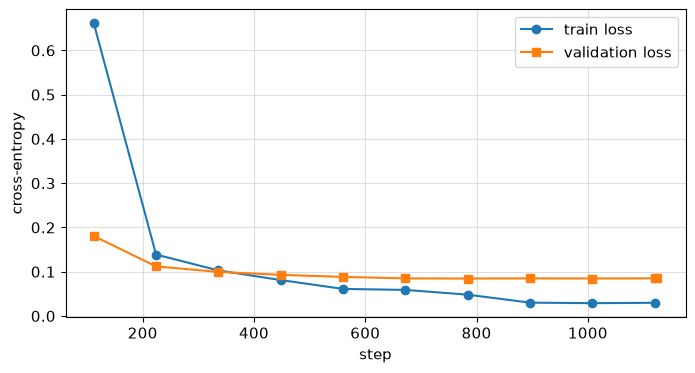

Train loss: 0.6614 -> 0.0298
Validation loss: 0.1807 -> 0.0850; минимум 0.0845


In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

print(f'Train loss: {train_curve[0][1]:.4f} -> {train_curve[-1][1]:.4f}')
print(f'Validation loss: {eval_curve[0][1]:.4f} -> {eval_curve[-1][1]:.4f}; минимум {min(v for _, v in eval_curve):.4f}')

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Для небольшой модели я взял learning rate `2e-4`, batch size 32 и три эпохи:
этого хватило, чтобы быстро проверить, учится ли модель на моих данных.
Batch 32 поместился на видеокарту, а три эпохи дали 1125 шагов обучения.
Использовал AdamW, weight decay 0,01, разогрев на первых 10% шагов и затем линейное снижение lr.
Разогрев нужен, чтобы в начале не менять предобученные веса слишком резко,
а weight decay — чтобы немного сдерживать переобучение. Перебор гиперпараметров я не делал,
поэтому не утверждаю, что это лучшие настройки.

Обучение заняло 38,7 секунды на NVIDIA GeForce RTX 5070.
Train loss между первым и последним замерами упал с 0,6614 до 0,0298,
а validation loss — с 0,1807 до 0,0850.
При этом минимум validation loss был чуть раньше — 0,0845, после чего улучшение остановилось,
хотя train loss продолжал падать. Это похоже на начало переобучения, но рост пока небольшой.
По этим кривым я бы сначала проверил выбор более ранней модели, а не просто добавлял эпохи.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    # ваш код
    tp = predicted = actual = 0
    for gold_row, pred_row in zip(gold, pred):
        for g, p in zip(gold_row, pred_row):
            tp += p != 'O' and p == g
            predicted += p != 'O'
            actual += g != 'O'
    return 2 * tp / (predicted + actual) if predicted + actual else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

final = {}       # ваш код: метрики на test: f1_micro, f1_macro, precision, recall, token_f1, per_type
val_pred = []    # предсказанные теги validation (список списков), нужны в 5.1

def evaluate(model, ds):
    gold = [[LABEL_NAMES[t] for t in row] for row in ds['ner_tags']]
    pred = predict_word_tags(model, ds['tokens'])
    report = classification_report(gold, pred, output_dict=True, zero_division=0)
    result = entity_scores(gold, pred)
    result['token_f1'] = token_f1(gold, pred)
    result['per_type'] = {kind: report[kind] for kind in ENTITY_TYPES if kind in report}
    print(classification_report(gold, pred, digits=4, zero_division=0))
    print('Token F1:', result['token_f1'])
    return result, pred

print('Validation')
val_scores, val_pred = evaluate(model, data['validation'])
print('Test')
final, test_pred = evaluate(model, data['test'])
worst_type = min(final['per_type'], key=lambda kind: final['per_type'][kind]['f1-score'])
print('Самый низкий F1:', worst_type, final['per_type'][worst_type]['f1-score'])

print('Число сущностей этого типа в train:', stats['train']['entities'].get(worst_type, 0))
print('Token F1 - entity F1:', final['token_f1'] - final['f1_micro'])

Validation
              precision    recall  f1-score   support

         LOC     0.8720    0.9016    0.8865      1118
        MISC     0.6395    0.6963    0.6667       349
         ORG     0.6603    0.6731    0.6667       361
         PER     0.8177    0.8601    0.8384       579

   micro avg     0.7927    0.8276    0.8098      2407
   macro avg     0.7474    0.7828    0.7646      2407
weighted avg     0.7935    0.8276    0.8101      2407

Token F1: 0.8345323741007195
Test
              precision    recall  f1-score   support

         LOC     0.8877    0.9089    0.8981      1174
        MISC     0.6475    0.7096    0.6771       365
         ORG     0.6526    0.7026    0.6767       417
         PER     0.8101    0.8496    0.8294       472

   micro avg     0.7934    0.8320    0.8122      2428
   macro avg     0.7495    0.7927    0.7703      2428
weighted avg     0.7961    0.8320    0.8135      2428

Token F1: 0.8434611304743143
Самый низкий F1: ORG 0.6766743648960738
Число сущностей 

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** На test хуже всего получился ORG: F1=0,6767; MISC почти такой же — 0,6771.
В train у ORG 2614 сущностей против 8915 у LOC, так что примеров организаций заметно меньше.
Названия организаций бывают разными по форме, а их границы и тип не всегда очевидны.
Это возможные причины ошибок, но отдельно длины спанов по типам я не сравнивал,
поэтому объяснять результат только длиной было бы неправильно.

Micro-F1 на test равен 0,8122, а macro-F1 — 0,7703.
Micro считает все сущности вместе, поэтому частый и хорошо распознаваемый LOC
(F1=0,8981) сильнее влияет на общий результат. В macro каждый тип имеет одинаковый вес,
и низкие результаты ORG и MISC заметнее снижают оценку.

Token-F1=0,8435 выше F1 по сущностям на 0,0312, то есть примерно на 3,12 процентного пункта.
Если модель правильно пометила только часть длинного названия, token-F1 засчитает верные слова,
а entity-F1 не засчитает сущность целиком. Для пользователя, которому нужны полные имена и названия,
я бы смотрел прежде всего на F1 по сущностям.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    # ваш код
    def overlap(a, b):
        return max(a[0], b[0]) < min(a[1], b[1])

    result = []
    for gold in gold_spans:
        same_type = [p for p in pred_spans if overlap(gold, p) and p[2] == gold[2]]
        other_type = [p for p in pred_spans if overlap(gold, p)]
        if gold in pred_spans:
            result.append(('correct', gold, gold))
        elif same_type:
            result.append(('boundary', gold, same_type[0]))
        elif other_type:
            result.append(('type', gold, other_type[0]))
        else:
            result.append(('missed', gold, None))
    for pred in pred_spans:
        if not any(overlap(gold, pred) for gold in gold_spans):
            result.append(('spurious', None, pred))
    return result

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = {}   # ваш код: {категория: число} на validation, затем доли и 5+ примеров

counts = collections.Counter({category: 0 for category in ERROR_CATEGORIES})
examples = collections.defaultdict(list)
for words, gold, pred in zip(val_tokens, val_gold, val_pred):
    for category, g, p in categorize_errors(bio_to_spans(gold), bio_to_spans(pred)):
        counts[category] += 1
        if category != 'correct' and len(examples[category]) < 2:
            examples[category].append((words, g, p))
errors = dict(counts)
total_errors = sum(n for category, n in errors.items() if category != 'correct')
print(errors)
print({category: n / max(1, total_errors) for category, n in errors.items() if category != 'correct'})
for category, rows in examples.items():
    for words, gold, pred in rows:
        print(category, ':', ' '.join(words))
        print('Разметка:', None if gold is None else (gold, ' '.join(words[gold[0]:gold[1]])))
        print('Предсказание:', None if pred is None else (pred, ' '.join(words[pred[0]:pred[1]])))
main_error = max((c for c in errors if c != 'correct'), key=errors.get)
print('Самая частая ошибка:', main_error)

{'correct': 1992, 'boundary': 133, 'type': 228, 'missed': 54, 'spurious': 106}
{'boundary': 0.255278310940499, 'type': 0.43761996161228406, 'missed': 0.1036468330134357, 'spurious': 0.2034548944337812}
spurious : 8 февраля бойцы МПЛА при кубинской поддержке заняли важный стратегический город Санту-Антониу-ду-Заири .
Разметка: None
Предсказание: ((3, 4, 'ORG'), 'МПЛА')
spurious : Сведения , данные апостолами Лукой и Иоанном , носят относительно противоречивый характер .
Разметка: None
Предсказание: ((3, 4, 'PER'), 'апостолами')
boundary : Брокхауз стал профессором в университете Мак-Мастера в Канаде , где и оставался до пенсии в 1984 г .
Разметка: ((4, 6, 'LOC'), 'университете Мак-Мастера')
Предсказание: ((5, 6, 'LOC'), 'Мак-Мастера')
boundary : 23 декабря 2007 года подписал двухлетний контракт с новосибирской « Сибирью » , осуществив мечту играть за родной город .
Разметка: ((10, 12, 'ORG'), 'Сибирью »')
Предсказание: ((9, 12, 'ORG'), '« Сибирью »')
type : Согласно предъявленному в дал

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Чаще всего модель ошибается в типе: 228 из 521 ошибок на validation, или 43,8%.
Остальные — границы: 133 (25,5%), лишние сущности: 106 (20,3%) и пропуски: 54 (10,4%).
Например, «Кидда» в тексте об обвинении в пиратстве размечено как PER, а модель выбрала LOC.
По контексту это похоже именно на ошибку модели: имя она нашла, но тип определила неверно.
Во втором примере такого рода, «епископа Содора», уже не так просто понять,
обозначает ли выделенное слово человека или место, поэтому с разметкой я бы не соглашался автоматически.

Ошибки границ в показанных примерах связаны с составными названиями и кавычками:
у «университете Мак-Мастера» модель выделила только «Мак-Мастера»,
а у «Сибири» добавила открывающую кавычку, которой нет в размеченном спане.
Последний случай выглядит как непоследовательность разметки, а не серьезная ошибка распознавания.
Среди лишних сущностей есть «апостолами» — обычное обозначение людей, которое модель ошибочно сделала PER.
Но «МПЛА», предсказанное как ORG и отсутствующее в разметке, похоже на пропущенную при разметке организацию.
Это мои предположения по контексту, а не результат отдельной ручной проверки.
Оба показанных пропуска — названия произведений в одном длинном предложении;
здесь я бы проверил и редкость названий, и влияние обрезки текста.

Чтобы уменьшить ошибки типа, я бы сначала посмотрел, какие пары типов чаще путаются,
и добавил в train проверенные примеры с похожими именами в разном контексте.
Править validation ради роста метрики я бы не стал: спорные случаи лучше разобрать отдельно.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
ablation = {}   # ваш код

set_seed(SEED)
frozen_model = make_model()
frozen_history, frozen_seconds = train_ner(frozen_model, tokenized['train'], tokenized['validation'],
                                          freeze_encoder=True, out_dir='runs/frozen')
frozen_scores, _ = evaluate(frozen_model, data['validation'])
ablation = dict(setting=ABLATION,
                full=dict(f1=val_scores['f1_micro'], seconds=train_seconds,
                          trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)),
                frozen=dict(f1=frozen_scores['f1_micro'], seconds=frozen_seconds,
                            trainable_params=sum(p.numel() for p in frozen_model.parameters() if p.requires_grad)))
print(json.dumps(ablation, indent=2))
del frozen_model

print('Изменение F1 при заморозке:', frozen_scores['f1_micro'] - val_scores['f1_micro'])
print('Отношение времени полного обучения к заморозке:', train_seconds / frozen_seconds)

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.704', 'grad_norm': '2.974', 'learning_rate': '0.0001965', 'epoch': '0.2987'}
{'eval_loss': '1.003', 'eval_runtime': '0.1873', 'eval_samples_per_second': '8011', 'eval_steps_per_second': '128.2', 'epoch': '0.2987'}
{'loss': '0.5888', 'grad_norm': '0.4681', 'learning_rate': '0.0001783', 'epoch': '0.5973'}
{'eval_loss': '0.4209', 'eval_runtime': '0.1819', 'eval_samples_per_second': '8247', 'eval_steps_per_second': '132', 'epoch': '0.5973'}
{'loss': '0.3679', 'grad_norm': '0.4079', 'learning_rate': '0.0001561', 'epoch': '0.896'}
{'eval_loss': '0.3459', 'eval_runtime': '0.1908', 'eval_samples_per_second': '7861', 'eval_steps_per_second': '125.8', 'epoch': '0.896'}
{'loss': '0.3294', 'grad_norm': '0.3317', 'learning_rate': '0.000134', 'epoch': '1.195'}
{'eval_loss': '0.3082', 'eval_runtime': '0.1911', 'eval_samples_per_second': '7849', 'eval_steps_per_second': '125.6', 'epoch': '1.195'}
{'loss': '0.3025', 'grad_norm': '0.3015', 'learning_rate': '0.0001119', 'epoch': '1.493'}
{'ev

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** При заморозке энкодера validation F1 упал с 0,8098 до 0,5002 — примерно на 30,95
процентного пункта. Зато обучение сократилось с 38,7 до 12,4 секунды, то есть стало быстрее в 3,12 раза.
В полной модели обучались 29 098 929 параметров, а с заморозкой — только 2817 параметров головы.
Данные, seed, начальная модель и остальные настройки в этих двух запусках одинаковые.

Получается, что в моем эксперименте готовых признаков энкодера и одной обученной линейной головы
для хорошего NER не хватило: заметный выигрыш дала адаптация самого энкодера.
За экономию примерно 26 секунд я бы не стал терять столько качества.
Но это сравнение только с одним seed и одним learning rate.
Для более надежного вывода я бы повторил запуски с несколькими seed
и отдельно подобрал learning rate для варианта с заморозкой.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Я дообучил rubert-tiny2 на 12 000 предложений за три эпохи;
обучение заняло 38,7 секунды на RTX 5070.
На validation F1 вырос с 0,4380 у словарного бейзлайна и 0,0307 у случайной головы до 0,8098
у дообученной модели, так что обучение явно помогло.
На test получились micro-F1=0,8122 и macro-F1=0,7703 — результат близок к validation.
Лучше всего модель распознает LOC (F1=0,8981), а сложнее всего ей даются ORG (0,6767)
и MISC (0,6771).
Самая частая проблема на validation — неверный тип сущности: 228 из 521 ошибок,
причем среди показанных расхождений есть и подозрительные места в самой разметке.
Заморозка энкодера ускорила обучение с 38,7 до 12,4 секунды,
но снизила validation F1 до 0,5002, поэтому я бы выбрал полное дообучение.
Ограничения этой работы — автоматическая разметка, подмножество данных, обрезка длинных текстов
и только один seed: по такому запуску нельзя судить о стабильности результата или качестве на других текстах.
Дальше я бы проверил спорные примеры, повторил обучение с несколькими seed
и попробовал брать модель с более раннего шага, поскольку validation loss к концу уже почти не улучшался.

In [29]:
print(f"Я дообучил rubert-tiny2 на {len(data['train'])} предложениях за {EPOCHS} эпох(и).")
print(f"На validation словарь получил F1={baseline['majority']['f1_micro']:.4f}, "
      f"случайная голова — {baseline['random_head']['f1_micro']:.4f}, "
      f"а дообученная модель — {val_scores['f1_micro']:.4f}.")
print(f"На test micro-F1={final['f1_micro']:.4f}, macro-F1={final['f1_macro']:.4f}, "
      f"token-F1={final['token_f1']:.4f}.")
print(f"Хуже всего распознается {worst_type}: F1={final['per_type'][worst_type]['f1-score']:.4f}.")
print(f"Самая частая категория ошибок — {main_error}: {errors[main_error]} из {total_errors} ошибок.")
print(f"Полное дообучение заняло {train_seconds:.1f} с на {DEVICE_NAME}, "
      f"заморозка — {frozen_seconds:.1f} с и дала validation F1={frozen_scores['f1_micro']:.4f}.")
print("Основные ограничения — автоматическая разметка, ограниченное число примеров и один seed; "
      "дальше я бы проверил разметку трудных случаев и повторил обучение с несколькими seed.")

Я дообучил rubert-tiny2 на 12000 предложениях за 3 эпох(и).
На validation словарь получил F1=0.4380, случайная голова — 0.0307, а дообученная модель — 0.8098.
На test micro-F1=0.8122, macro-F1=0.7703, token-F1=0.8435.
Хуже всего распознается ORG: F1=0.6767.
Самая частая категория ошибок — type: 228 из 521 ошибок.
Полное дообучение заняло 38.7 с на NVIDIA GeForce RTX 5070, заморозка — 12.4 с и дала validation F1=0.5002.
Основные ограничения — автоматическая разметка, ограниченное число примеров и один seed; дальше я бы проверил разметку трудных случаев и повторил обучение с несколькими seed.


### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "Babelscape/wikineural", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 12000, "n_val": 1500, "n_test": 1500, "params_total": 29098929, "ablation": {"setting": "freeze", "full": {"f1": 0.8097560975609756, "seconds": 38.699763599957805, "trainable_params": 29098929}, "frozen": {"f1": 0.5002286236854138, "seconds": 12.416677100001834, "trainable_params": 2817}}, "errors": {"correct": 1992, "boundary": 133, "type": 228, "missed": 54, "spurious": 106}, "device": "NVIDIA G
final F1 micro 0.8122


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [31]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Бонус не выполнял.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [32]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** Бонус не выполнял.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [33]:
if '6.3' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Бонус не выполнял.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [34]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Бонус не выполнял.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

In [35]:
if '6.5' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Бонус не выполнял.